**Cell 00 · Cell index** — each cell is prefixed with `Cell NN · name` (also in cell metadata `cell_label`).

- **01 · Intro**
- **02 · Load & clean**
- **03 · Unified summary overview**
- **04 · Unified summary code**
- **05 · Summary plots overview**
- **06 · Summary plots code**
- **07 · Modeling target overview**
- **08 · Modeling target code**
- **09 · Scale predictors overview**
- **10 · Scale & modeling table code**
- **11 · BMI skew — transform & scale**
- **12 · Binary modeling overview**
- **13 · Logistic regression (fit & evaluation)**
- **14 · Random forest (fit & evaluation)**
- **15 · Model comparison**


**Cell 01 · Intro**

# Diabetes Prediction Model (5050 Split)

Pipeline for **BRFSS 2015** health indicators ([UCI / Kaggle diabetes health indicators](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators)): load and clean the pre-balanced **`diabetes_binary_5050split_health_indicators_BRFSS2015.csv`** subsample (same steps as the full-cohort notebook), unified descriptive summary, exploratory plots, binary modeling target **`diabetes_outcome`**, and a standardized modeling matrix **`df_model_scaled`**.

Each row is one survey respondent. **Target:** diabetes (`Diabetes_binary` → **`diabetes_outcome`**, 0/1). Predictors are the other BRFSS fields (including **`heart_disease_or_attack`**).

**Why this notebook:** The full BRFSS file is ~**86% / 14%** (no diabetes / diabetes), so overall **accuracy** is easy to inflate. This CSV is UCI’s **50/50 subsample**—equal counts of each label—so you can see how well features separate the classes without real-world prevalence in the way.

**What goes into the fit:** Same as the full-cohort notebook: each CV fold passes two **`class_weight`** values into the models (how costly wrong answers are per label). Here the weights are usually **1 and 1** because the sample is already balanced; **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS`** in Cell 13 can still bump the diabetes weight. We do **not** resample rows inside the notebook.

For models meant to reflect real U.S. prevalence, use **`Diabetes Prediction Model.ipynb`** (14% diabetes) with its higher diabetes weight.


In [28]:
# Cell 02 · Load & clean
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

DATA_DIR = Path(".")
DATA_FILE = DATA_DIR / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
COMPILED_DIR = DATA_DIR / "compiled"
COMPILED_DIR.mkdir(exist_ok=True)

COLUMN_RENAME = {
    "Diabetes_binary": "diabetes_binary",
    "HighBP": "high_bp",
    "HighChol": "high_chol",
    "CholCheck": "chol_check",
    "BMI": "bmi",
    "Smoker": "smoker",
    "Stroke": "stroke",
    "HeartDiseaseorAttack": "heart_disease_or_attack",
    "PhysActivity": "phys_activity",
    "Fruits": "fruits",
    "Veggies": "veggies",
    "HvyAlcoholConsump": "hvy_alcohol_consump",
    "AnyHealthcare": "any_healthcare",
    "NoDocbcCost": "no_docbc_cost",
    "GenHlth": "gen_hlth",
    "MentHlth": "ment_hlth",
    "PhysHlth": "phys_hlth",
    "DiffWalk": "diff_walk",
    "Sex": "sex",
    "Age": "age",
    "Education": "education",
    "Income": "income",
}

df_raw = pd.read_csv(DATA_FILE)
df_raw = df_raw.rename(columns=COLUMN_RENAME)

# BRFSS export: numeric 0/1 and coded ordinals; enforce numeric dtypes
for col in df_raw.columns:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

n_before = len(df_raw)
df_raw = df_raw.dropna(how="any")
if len(df_raw) < n_before:
    print(f"Dropped {n_before - len(df_raw):,} rows with missing values")

dup = int(df_raw.duplicated().sum())
if dup:
    print(f"Duplicate rows: {dup:,} (kept for BRFSS survey-weight fidelity)")

print(f"Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Diabetes prevalence: {df_raw['diabetes_binary'].mean():.3%}")

# Working frame for summaries (predictors + outcome; no extra encoding required)
df = df_raw.copy()
df.head()


Duplicate rows: 1,635 (kept for BRFSS survey-weight fidelity)
Loaded: 70,692 rows × 22 columns
Diabetes prevalence: 50.000%


,diabetes_binary,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,...,any_healthcare,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


**Cell 03 · Unified summary overview**

## Unified summary table

One row per column: data type, **measurement level** (BRFSS coding), counts, central tendency, spread, skew, and IQR outliers for **ratio** / **interval** fields only.


In [29]:
# Cell 04 · Unified summary code
measurement_levels = {
    "diabetes_binary": "nominal (binary)",
    "high_bp": "nominal (binary)",
    "high_chol": "nominal (binary)",
    "chol_check": "nominal (binary)",
    "bmi": "ratio",
    "smoker": "nominal (binary)",
    "stroke": "nominal (binary)",
    "heart_disease_or_attack": "nominal (binary)",
    "phys_activity": "nominal (binary)",
    "fruits": "nominal (binary)",
    "veggies": "nominal (binary)",
    "hvy_alcohol_consump": "nominal (binary)",
    "any_healthcare": "nominal (binary)",
    "no_docbc_cost": "nominal (binary)",
    "gen_hlth": "ordinal",
    "ment_hlth": "ordinal",
    "phys_hlth": "ordinal",
    "diff_walk": "nominal (binary)",
    "sex": "nominal (binary)",
    "age": "ordinal",
    "education": "ordinal",
    "income": "ordinal",
}


def column_mode(series: pd.Series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else np.nan


def iqr_outlier_count(series: pd.Series) -> int:
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) < 4:
        return 0
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower) | (values > upper)).sum())


rows = []
for col in df.columns:
    s = df[col]
    is_numeric = pd.api.types.is_numeric_dtype(s)
    level = measurement_levels.get(col, "nominal")
    distribution_stats = level in {"interval", "ratio"}

    rows.append(
        {
            "column": col,
            "data_type": str(s.dtype),
            "measurement_level": level,
            "count": int(s.count()),
            "missing": int(s.isna().sum()),
            "unique_values": int(s.nunique()),
            "mean": float(s.mean()) if is_numeric else np.nan,
            "median": float(s.median()) if is_numeric else np.nan,
            "mode": column_mode(s),
            "min": float(s.min()) if is_numeric else np.nan,
            "max": float(s.max()) if is_numeric else np.nan,
            "range": float(s.max() - s.min()) if is_numeric else np.nan,
            "skew": float(stats.skew(s.dropna(), bias=False))
            if distribution_stats and s.notna().sum() >= 3
            else np.nan,
            "iqr_outlier_count": iqr_outlier_count(s)
            if distribution_stats
            else np.nan,
        }
    )

unified_summary = pd.DataFrame(rows).set_index("column")
for c in ["mean", "median", "min", "max", "range", "skew"]:
    unified_summary[c] = unified_summary[c].round(3)
unified_summary["iqr_outlier_count"] = unified_summary["iqr_outlier_count"].astype("Int64")
unified_summary


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
diabetes_binary,float64,nominal (binary),70692,0,2,0.500,0.5,0.0,0.0,1.0,1.0,NaN,<NA>
high_bp,float64,nominal (binary),70692,0,2,0.563,1.0,1.0,0.0,1.0,1.0,NaN,<NA>
high_chol,float64,nominal (binary),70692,0,2,0.526,1.0,1.0,0.0,1.0,1.0,NaN,<NA>
chol_check,float64,nominal (binary),70692,0,2,0.975,1.0,1.0,0.0,1.0,1.0,NaN,<NA>
bmi,float64,ratio,70692,0,80,29.857,29.0,27.0,12.0,98.0,86.0,1.719,2181
smoker,float64,nominal (binary),70692,0,2,0.475,0.0,0.0,0.0,1.0,1.0,NaN,<NA>
stroke,float64,nominal (binary),70692,0,2,0.062,0.0,0.0,0.0,1.0,1.0,NaN,<NA>
heart_disease_or_attack,float64,nominal (binary),70692,0,2,0.148,0.0,0.0,0.0,1.0,1.0,NaN,<NA>
phys_activity,float64,nominal (binary),70692,0,2,0.703,1.0,1.0,0.0,1.0,1.0,NaN,<NA>


**Cell 05 · Summary plots overview**

Key BRFSS distributions: **diabetes** outcome, **age** bracket by **sex**, **BMI**, and self-rated **general health**.


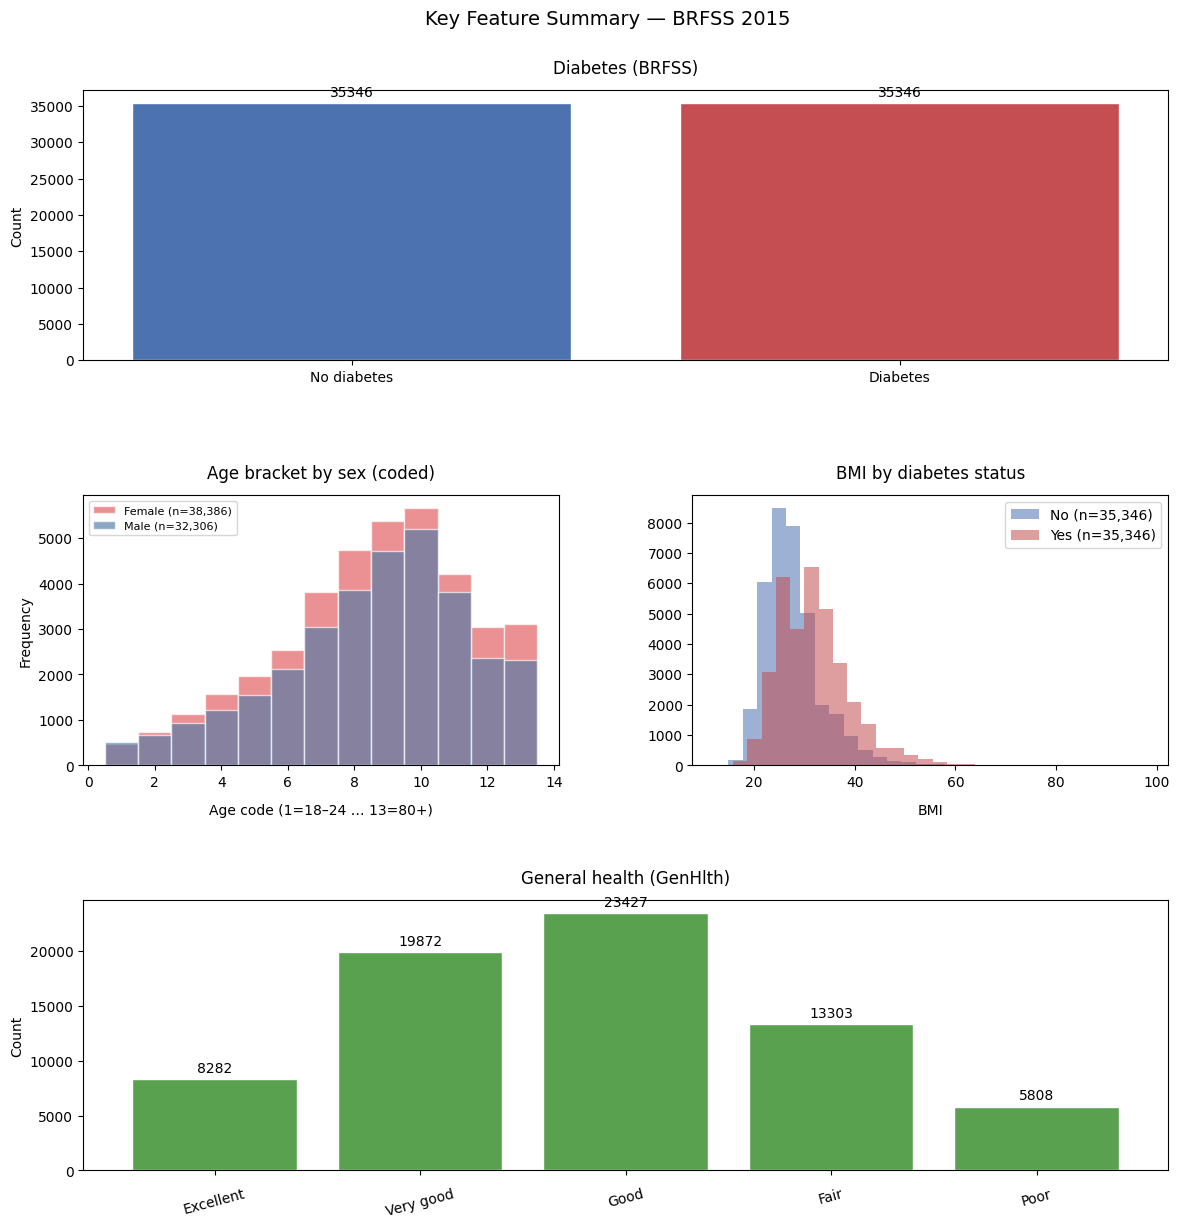

In [30]:
# Cell 06 · Summary plots code
import matplotlib.pyplot as plt

AGE_LABELS = {
    1: "18–24",
    2: "25–29",
    3: "30–34",
    4: "35–39",
    5: "40–44",
    6: "45–49",
    7: "50–54",
    8: "55–59",
    9: "60–64",
    10: "65–69",
    11: "70–74",
    12: "75–79",
    13: "80+",
}
GEN_HLTH_LABELS = {
    1: "Excellent",
    2: "Very good",
    3: "Good",
    4: "Fair",
    5: "Poor",
}

fig = plt.figure(figsize=(14, 13.5))
grid = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 1.0], hspace=0.50, wspace=0.28)

ax_outcome = fig.add_subplot(grid[0, :])
outcome_counts = df_raw["diabetes_binary"].value_counts().sort_index()
bars = ax_outcome.bar(
    ["No diabetes", "Diabetes"],
    [outcome_counts.get(0, 0), outcome_counts.get(1, 0)],
    color=["#4C72B0", "#C44E52"],
    edgecolor="white",
)
ax_outcome.set_title("Diabetes (BRFSS)", pad=12)
ax_outcome.set_ylabel("Count")
ax_outcome.bar_label(bars, padding=3, fmt="%d")

sex_colors = {0: "#E15759", 1: "#4E79A7"}
sex_labels = {0: "Female", 1: "Male"}

ax_age = fig.add_subplot(grid[1, 0])
for sex_code, label in sex_labels.items():
    ages = df_raw.loc[df_raw["sex"] == sex_code, "age"].dropna()
    ax_age.hist(
        ages,
        bins=np.arange(0.5, 14.5, 1),
        alpha=0.65,
        label=f"{label} (n={len(ages):,})",
        color=sex_colors[sex_code],
        edgecolor="white",
    )
ax_age.set_title("Age bracket by sex (coded)", pad=12)
ax_age.set_xlabel("Age code (1=18–24 … 13=80+)", labelpad=10)
ax_age.set_ylabel("Frequency")
ax_age.legend(fontsize=8)

ax_bmi = fig.add_subplot(grid[1, 1])
for outcome, name, color in (
    (0, "No", "#4C72B0"),
    (1, "Yes", "#C44E52"),
):
    subset = df_raw.loc[df_raw["diabetes_binary"] == outcome, "bmi"]
    ax_bmi.hist(subset, bins=30, alpha=0.55, label=f"{name} (n={len(subset):,})", color=color)
ax_bmi.set_title("BMI by diabetes status", pad=12)
ax_bmi.set_xlabel("BMI", labelpad=10)
ax_bmi.legend()

ax_gen = fig.add_subplot(grid[2, :])
gen_counts = df_raw["gen_hlth"].value_counts().sort_index()
x = [GEN_HLTH_LABELS.get(int(i), str(i)) for i in gen_counts.index]
bars = ax_gen.bar(x, gen_counts.values, color="#59A14F", edgecolor="white")
ax_gen.set_title("General health (GenHlth)", pad=12)
ax_gen.set_ylabel("Count")
ax_gen.bar_label(bars, padding=3, fmt="%d")
ax_gen.tick_params(axis="x", rotation=15, pad=8)

fig.suptitle("Key Feature Summary — BRFSS 2015", fontsize=14, y=0.98)
fig.subplots_adjust(top=0.92, hspace=0.72, wspace=0.28, bottom=0.12)
plt.show()


**Cell 07 · Modeling target overview**

## Modeling target (binary)

**`diabetes_outcome`** is the binary label for modeling (0 = no diabetes, 1 = diabetes). The source column **`diabetes_binary`** is dropped from predictors to avoid leakage; **`heart_disease_or_attack`** and other BRFSS fields remain as features.


In [31]:
# Cell 08 · Modeling target code
from IPython.display import display

DIABETES_OUTCOME_COL = "diabetes_outcome"

predictor_cols = [c for c in df.columns if c != "diabetes_binary"]
df_model = df[predictor_cols].copy()
df_model[DIABETES_OUTCOME_COL] = df_raw["diabetes_binary"].astype(int)

outcome_reference = pd.DataFrame(
    {
        "class_id": [0, 1],
        "label": ["No diabetes", "Diabetes"],
    }
)

print(f"Modeling table: {df_model.shape[0]:,} rows × {df_model.shape[1]} columns")
print(f"Outcome column: {DIABETES_OUTCOME_COL}")
display(outcome_reference)
print("\nClass counts:")
print(df_model[DIABETES_OUTCOME_COL].value_counts().sort_index().to_string())
df_model.head()


Modeling table: 70,692 rows × 22 columns
Outcome column: diabetes_outcome


,class_id,label
0,0,No diabetes
1,1,Diabetes



Class counts:
diabetes_outcome
0    35346
1    35346


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0,0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0,0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0,0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0,0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0,0


**Cell 09 · Scale predictors overview**

### Transform and scale continuous predictors

**`bmi`** is right-skewed (typical skew > 1). **`StandardScaler` alone does not remove skew** — it only centers and rescales. For logistic regression we want a smoother, more symmetric predictor so the **log-odds are approximately linear in BMI** and extreme values carry less leverage.

Pipeline for ratio columns (currently **`bmi`** only): **`PowerTransformer`** (Yeo–Johnson) → **`StandardScaler`**. Ordinal BRFSS codes and binary indicators stay on their original scales. Output: **`df_model_scaled`** for downstream classifiers.


In [32]:
# Cell 10 · Scale & modeling table code
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

if "df_model" not in globals():
    raise NameError("Run Cell 08 (modeling target) first.")
if "measurement_levels" not in globals():
    raise NameError("Run Cell 04 (unified summary) first.")

CONTINUOUS_LEVELS = {"ratio", "interval"}

MODELING_PREDICTOR_COLS = [c for c in df_model.columns if c != DIABETES_OUTCOME_COL]
df_model_modeling = df_model[MODELING_PREDICTOR_COLS + [DIABETES_OUTCOME_COL]].copy()

CONTINUOUS_PREDICTOR_COLS = [
    c
    for c in MODELING_PREDICTOR_COLS
    if measurement_levels.get(c) in CONTINUOUS_LEVELS
]
ORDINAL_OR_NOMINAL_COLS = [
    c for c in MODELING_PREDICTOR_COLS if c not in CONTINUOUS_PREDICTOR_COLS
]

df_model_scaled = df_model_modeling.copy()
dm_continuous_preprocessors: dict[str, Pipeline] = {}
for col in CONTINUOUS_PREDICTOR_COLS:
    pipe = Pipeline(
        [
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("standardize", StandardScaler()),
        ]
    )
    values = df_model_modeling[[col]].astype(float)
    df_model_scaled[col] = pipe.fit_transform(values).ravel()
    dm_continuous_preprocessors[col] = pipe

print(
    f"Modeling table: {df_model_modeling.shape[0]:,} rows × {df_model_modeling.shape[1]} columns "
    f"({len(MODELING_PREDICTOR_COLS)} predictors + {DIABETES_OUTCOME_COL})"
)
print(
    f"Continuous columns (Yeo–Johnson + StandardScaler) ({len(CONTINUOUS_PREDICTOR_COLS)}): "
    f"{CONTINUOUS_PREDICTOR_COLS}"
)
print(f"Unscaled predictors ({len(ORDINAL_OR_NOMINAL_COLS)}): {ORDINAL_OR_NOMINAL_COLS}")


def _count_iqr_outliers(series: pd.Series) -> int:
    if "iqr_outlier_count" in globals():
        return int(iqr_outlier_count(series))
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum())


def _final_modeling_feature_summary(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    rows: list[dict] = []
    for col in features:
        s = pd.to_numeric(frame[col], errors="coerce")
        vals = s.dropna()
        level = measurement_levels.get(col, "unknown")
        distribution_stats = level in {"interval", "ratio"}
        rows.append(
            {
                "feature": col,
                "measurement_level": level,
                "transformed_scaled": col in CONTINUOUS_PREDICTOR_COLS,
                "count": int(vals.count()),
                "mean": round(float(vals.mean()), 4) if len(vals) else None,
                "std": round(float(vals.std(ddof=0)), 4) if len(vals) else None,
                "min": round(float(vals.min()), 4) if len(vals) else None,
                "max": round(float(vals.max()), 4) if len(vals) else None,
                "skew": round(float(vals.skew()), 3) if len(vals) >= 3 else None,
                "iqr_outliers": _count_iqr_outliers(vals)
                if distribution_stats and len(vals) >= 4
                else None,
            }
        )
    return pd.DataFrame(rows).set_index("feature")


print("\n=== Final modeling matrix — feature summary ===")
display(_final_modeling_feature_summary(df_model_scaled, MODELING_PREDICTOR_COLS))

print("\n=== Final modeling matrix — first rows ===")
display(df_model_scaled.head(10))

export_path = COMPILED_DIR / "brfss_diabetes_modeling_table_5050split.parquet"
try:
    df_model_scaled.to_parquet(export_path, index=False)
    print(f"\nSaved: {export_path}")
except Exception as exc:
    csv_path = COMPILED_DIR / "brfss_diabetes_modeling_table_5050split.csv"
    df_model_scaled.to_csv(csv_path, index=False)
    print(f"\nParquet unavailable ({exc}); saved CSV: {csv_path}")


Modeling table: 70,692 rows × 22 columns (21 predictors + diabetes_outcome)
Continuous columns (Yeo–Johnson + StandardScaler) (1): ['bmi']
Unscaled predictors (20): ['high_bp', 'high_chol', 'chol_check', 'smoker', 'stroke', 'heart_disease_or_attack', 'phys_activity', 'fruits', 'veggies', 'hvy_alcohol_consump', 'any_healthcare', 'no_docbc_cost', 'gen_hlth', 'ment_hlth', 'phys_hlth', 'diff_walk', 'sex', 'age', 'education', 'income']

=== Final modeling matrix — feature summary ===


,measurement_level,transformed_scaled,count,mean,std,min,max,skew,iqr_outliers
feature,,,,,,,,,
high_bp,nominal (binary),False,70692,0.5635,0.4960,0.0000,1.0000,-0.256,NaN
high_chol,nominal (binary),False,70692,0.5257,0.4993,0.0000,1.0000,-0.103,NaN
chol_check,nominal (binary),False,70692,0.9753,0.1553,0.0000,1.0000,-6.119,NaN
bmi,ratio,True,70692,-0.0000,1.0000,-5.5456,3.8983,-0.015,645.0
smoker,nominal (binary),False,70692,0.4753,0.4994,0.0000,1.0000,0.099,NaN
stroke,nominal (binary),False,70692,0.0622,0.2415,0.0000,1.0000,3.626,NaN
heart_disease_or_attack,nominal (binary),False,70692,0.1478,0.3549,0.0000,1.0000,1.985,NaN
phys_activity,nominal (binary),False,70692,0.7030,0.4569,0.0000,1.0000,-0.889,NaN
fruits,nominal (binary),False,70692,0.6118,0.4873,0.0000,1.0000,-0.459,NaN



=== Final modeling matrix — first rows ===


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0,0.0,1.0,-0.475483,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0,0
1,1.0,1.0,1.0,-0.475483,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0,0
2,0.0,0.0,1.0,-0.475483,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0,0
3,1.0,1.0,1.0,-0.111169,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0,0
4,0.0,0.0,1.0,0.055064,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0,0
5,0.0,0.0,1.0,-2.575063,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,7.0,0.0,0.0,0.0,1.0,4.0,7.0,0
6,0.0,1.0,1.0,-0.475483,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,13.0,5.0,6.0,0
7,0.0,0.0,1.0,0.360259,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,4.0,0.0,0.0,0.0,1.0,6.0,4.0,3.0,0
8,0.0,0.0,1.0,0.500736,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,3.0,0.0,0.0,0.0,0.0,3.0,6.0,8.0,0
9,0.0,0.0,1.0,-0.287673,1.0,0.0,0.0,0.0,1.0,1.0,...,0.0,3.0,0.0,6.0,0.0,1.0,6.0,4.0,4.0,0



Saved: compiled\brfss_diabetes_modeling_table_5050split.parquet


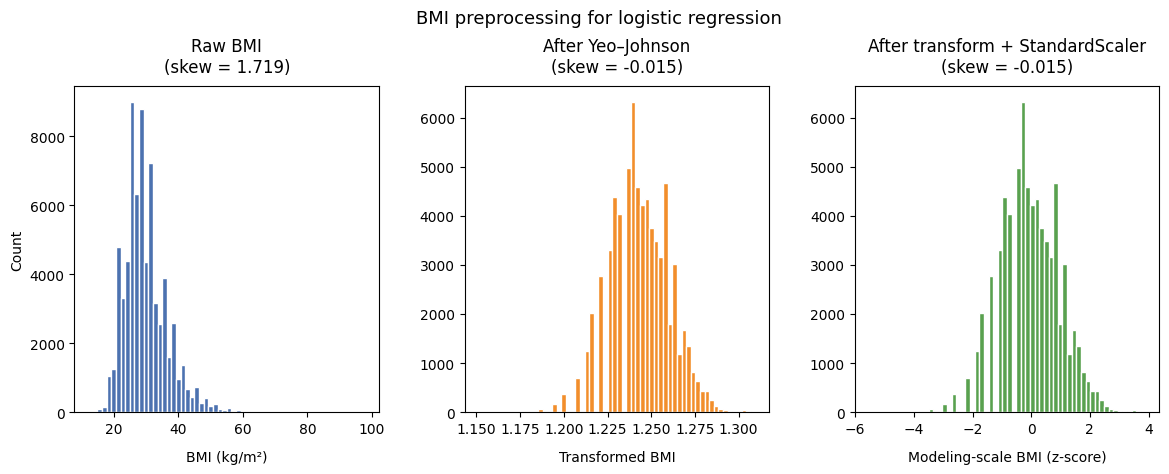

BMI skew: raw 1.7192 → Yeo–Johnson -0.0153 → modeling matrix -0.0153


In [33]:
# Cell 11 · BMI skew — Yeo–Johnson transform then StandardScaler
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import PowerTransformer

if "df_model_modeling" not in globals() or "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 (scale & modeling table) first.")

bmi_raw = df_model_modeling["bmi"].astype(float)
bmi_yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(
    bmi_raw.values.reshape(-1, 1)
).ravel()
bmi_model = df_model_scaled["bmi"].astype(float)

skew_raw = float(stats.skew(bmi_raw, bias=False))
skew_yj = float(stats.skew(bmi_yj, bias=False))
skew_model = float(stats.skew(bmi_model, bias=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].hist(bmi_raw, bins=60, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Raw BMI\n(skew = {skew_raw:.3f})", pad=10)
axes[0].set_xlabel("BMI (kg/m²)", labelpad=10)
axes[0].set_ylabel("Count")

axes[1].hist(bmi_yj, bins=60, color="#F28E2B", edgecolor="white")
axes[1].set_title(f"After Yeo–Johnson\n(skew = {skew_yj:.3f})", pad=10)
axes[1].set_xlabel("Transformed BMI", labelpad=10)

axes[2].hist(bmi_model, bins=60, color="#59A14F", edgecolor="white")
axes[2].set_title(f"After transform + StandardScaler\n(skew = {skew_model:.3f})", pad=10)
axes[2].set_xlabel("Modeling-scale BMI (z-score)", labelpad=10)

fig.suptitle("BMI preprocessing for logistic regression", fontsize=13, y=0.98)
fig.subplots_adjust(top=0.82, wspace=0.28, bottom=0.14)
plt.show()

print(
    f"BMI skew: raw {skew_raw:.4f} → Yeo–Johnson {skew_yj:.4f} → "
    f"modeling matrix {skew_model:.4f}"
)


**Cell 12 · Binary modeling overview**

Predict **`diabetes_outcome`** from **`df_model_scaled`** with **4-fold cross-validation** (stratified, shuffled, `random_state=42`). Each fold: train on 75%, test on 25%. We show metrics per fold, mean ± std, and **out-of-fold** ROC/confusion plots.

### Classes in this file (~50/50)

This subsample has about as many diabetes as non-diabetes rows. Cell 13 still computes **`class_weight = {0: w_no_diabetes, 1: w_diabetes}`** from each fold’s training set; the two weights are usually **equal**. Use **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS > 1`** only if you want to deliberately overweight diabetes errors anyway.

### Balanced accuracy (what it means)

**Balanced accuracy** is the average of “how often we get **no diabetes** right” and “how often we get **diabetes** right,” treating both groups equally. Range 0–1; **0.5** is no better than guessing both labels blindly. On a 50/50 file it is often close to overall **accuracy**, but it is still the right metric when you compare back to the **14%** full cohort.

We also report **ROC AUC**, **precision** / **recall** / **F1** for diabetes at threshold 0.5.

Random forest uses **`max_samples=30_000`** per tree on the 5050 subsample.


Full sample: n=70,692, diabetes prevalence = 50.000%
Majority-class baseline (always predict no diabetes): accuracy = 50.000%
Reference class_weight (full sample, emphasis=1.0): {0: 1.0000, 1: 1.0000} (ratio w1/w0 = 1.00×)
Logistic regression fold 1/4: AUC=0.8281, F1=0.7562, recall=0.7750, n_test=17,673
Logistic regression fold 2/4: AUC=0.8242, F1=0.7557, recall=0.7731, n_test=17,673
Logistic regression fold 3/4: AUC=0.8258, F1=0.7538, recall=0.7694, n_test=17,673
Logistic regression fold 4/4: AUC=0.8273, F1=0.7533, recall=0.7701, n_test=17,673

Logistic regression — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7492,0.0010
balanced_accuracy,0.7492,0.0010
precision,0.7384,0.0006
recall,0.7719,0.0023
f1,0.7548,0.0012
roc_auc,0.8263,0.0015



=== Logistic regression — out-of-fold evaluation ===
Logistic regression (4-fold OOF) — ROC AUC: 0.8263


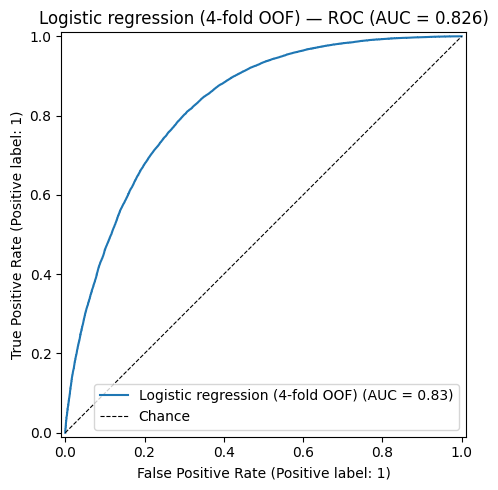

Confusion matrix (rows = true, columns = predicted):
[[25679  9667]
 [ 8063 27283]]


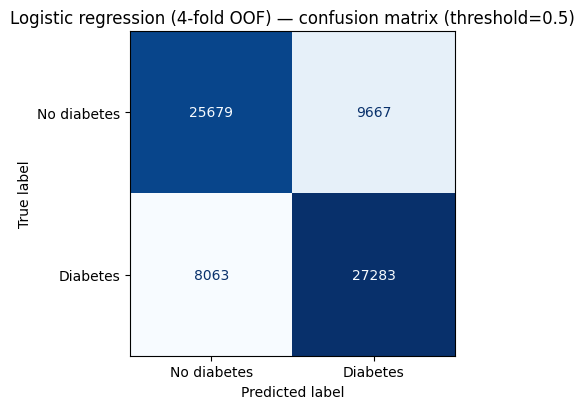

,value
accuracy,0.749194
balanced_accuracy,0.749194
precision,0.738376
recall,0.771884
f1,0.754758
roc_auc,0.826329


              precision    recall  f1-score   support

 No diabetes      0.761     0.727     0.743     35346
    Diabetes      0.738     0.772     0.755     35346

    accuracy                          0.749     70692
   macro avg      0.750     0.749     0.749     70692
weighted avg      0.750     0.749     0.749     70692


Coefficients — full-sample refit, target=diabetes_outcome, predictors=21
Intercept: -4.5859


,feature,coefficient,odds_ratio
2,chol_check,1.334440,3.797868
10,hvy_alcohol_consump,-0.736428,0.478821
0,high_bp,0.711362,2.036763
13,gen_hlth,0.584993,1.794978
1,high_chol,0.573229,1.773986
3,bmi,0.560220,1.751057
6,heart_disease_or_attack,0.253161,1.288090
17,sex,0.241295,1.272896
5,stroke,0.176651,1.193214
18,age,0.154564,1.167149


In [34]:
# Cell 13 · CV setup, class weights & logistic regression (4-fold)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold

if "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 first.")

DM_MODEL_RANDOM_STATE = 42
DM_CV_FOLDS = 4
DM_MINORITY_CLASS_WEIGHT_EMPHASIS = 1.0
DIABETES_CLASS_NAMES = ["No diabetes", "Diabetes"]

frame = df_model_scaled.copy()
X = frame[MODELING_PREDICTOR_COLS].astype(float)
y = frame[DIABETES_OUTCOME_COL].astype(int)
if X.isna().any().any():
    raise ValueError("Predictors contain NaN.")

overall_prev = float(y.mean())
majority_baseline_acc = float((y == 0).mean())
print(f"Full sample: n={len(y):,}, diabetes prevalence = {overall_prev:.3%}")
print(
    f"Majority-class baseline (always predict no diabetes): "
    f"accuracy = {majority_baseline_acc:.3%}"
)


def dm_class_weight_dict(y_train, emphasis: float = 1.0) -> dict[int, float]:
    """Two fit-time weights {0, 1}; class 1 upweighted by rarity × emphasis."""
    y_arr = np.asarray(y_train, dtype=int)
    n = len(y_arr)
    n0 = int((y_arr == 0).sum())
    n1 = int((y_arr == 1).sum())
    if n0 == 0 or n1 == 0:
        raise ValueError("Both classes required in training fold.")
    return {
        0: n / (2.0 * n0),
        1: (n / (2.0 * n1)) * emphasis,
    }


ref_weights = dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS)
print(
    f"Example class_weight fed to the model (full sample, emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}): "
    f"no diabetes (0)={ref_weights[0]:.4f}, diabetes (1)={ref_weights[1]:.4f} "
    f"(diabetes mistakes weighted {ref_weights[1] / ref_weights[0]:.2f}× more)"
)

dm_skf = StratifiedKFold(
    n_splits=DM_CV_FOLDS,
    shuffle=True,
    random_state=DM_MODEL_RANDOM_STATE,
)


def _dm_fold_metrics(y_true, y_pred, y_prob) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def _dm_binary_classification_eval(
    y_true,
    y_pred,
    y_prob_positive,
    class_names: list[str],
    model_title: str,
    cm_cmap: str = "Blues",
) -> pd.Series:
    """ROC/AUC, confusion matrix, and metrics (binary)."""
    test_auc = roc_auc_score(y_true, y_prob_positive)
    print(f"{model_title} — ROC AUC: {test_auc:.4f}")

    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_true,
        y_prob_positive,
        ax=ax,
        name=model_title,
    )
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
    ax.set_title(f"{model_title} — ROC (AUC = {test_auc:.3f})")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix (rows = true, columns = predicted):")
    print(cm)

    fig_cm, ax_cm = plt.subplots(figsize=(4.8, 4.2))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
        ax=ax_cm,
        cmap=cm_cmap,
        colorbar=False,
    )
    ax_cm.set_title(f"{model_title} — confusion matrix (threshold=0.5)")
    fig_cm.tight_layout()
    plt.show()

    metrics = pd.Series(_dm_fold_metrics(y_true, y_pred, y_prob_positive), name="value")
    display(metrics.to_frame())
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return metrics


def dm_run_cv(
    estimator,
    X_df: pd.DataFrame,
    y_s: pd.Series,
    cv: StratifiedKFold,
    emphasis: float,
    model_name: str,
) -> tuple[pd.DataFrame, pd.DataFrame, np.ndarray, np.ndarray]:
    oof_prob = np.zeros(len(y_s), dtype=float)
    oof_pred = np.zeros(len(y_s), dtype=int)
    fold_rows: list[dict] = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y_s), start=1):
        X_tr, X_te = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_tr, y_te = y_s.iloc[train_idx], y_s.iloc[test_idx]
        cw = dm_class_weight_dict(y_tr, emphasis)
        est = clone(estimator)
        est.set_params(class_weight=cw)
        est.fit(X_tr, y_tr)
        prob = est.predict_proba(X_te)[:, 1]
        pred = est.predict(X_te)
        oof_prob[test_idx] = prob
        oof_pred[test_idx] = pred
        m = _dm_fold_metrics(y_te, pred, prob)
        m["fold"] = fold
        m["n_train"] = len(y_tr)
        m["n_test"] = len(y_te)
        m["test_prevalence"] = float(y_te.mean())
        m["class_weight_1"] = cw[1]
        fold_rows.append(m)
        print(
            f"{model_name} fold {fold}/{DM_CV_FOLDS}: "
            f"AUC={m['roc_auc']:.4f}, F1={m['f1']:.4f}, "
            f"recall={m['recall']:.4f}, n_test={len(y_te):,}"
        )

    detail = pd.DataFrame(fold_rows).set_index("fold")
    metric_cols = [
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
    ]
    summary = pd.DataFrame(
        {
            "mean": detail[metric_cols].mean(),
            "std": detail[metric_cols].std(ddof=0),
        }
    )
    print(f"\n{model_name} — {DM_CV_FOLDS}-fold CV summary (mean ± std):")
    display(summary.round(4))
    return detail, summary, oof_pred, oof_prob


dm_logistic_base = LogisticRegression(max_iter=5000, solver="lbfgs")
(
    dm_logistic_cv_detail,
    dm_logistic_cv_summary,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
) = dm_run_cv(
    dm_logistic_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Logistic regression",
)

print("\n=== Logistic regression — out-of-fold evaluation ===")
dm_logistic_test_metrics = _dm_binary_classification_eval(
    y,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Logistic regression ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Blues",
)
dm_logistic_test_metrics.name = "logistic_regression"

dm_logistic_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
)
dm_logistic_model.fit(X, y)

dm_logistic_coef_table = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "coefficient": dm_logistic_model.coef_.ravel(),
    }
)
dm_logistic_coef_table["odds_ratio"] = np.exp(dm_logistic_coef_table["coefficient"])

print(
    f"\nCoefficients — full-sample refit, target={DIABETES_OUTCOME_COL}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}"
)
print(f"Intercept: {float(dm_logistic_model.intercept_[0]):.4f}")
display(
    dm_logistic_coef_table.sort_values(
        "coefficient", key=lambda s: s.abs(), ascending=False
    ).head(15)
)


Random forest fold 1/4: AUC=0.8167, F1=0.7532, recall=0.7878, n_test=17,673
Random forest fold 2/4: AUC=0.8181, F1=0.7549, recall=0.7878, n_test=17,673
Random forest fold 3/4: AUC=0.8158, F1=0.7507, recall=0.7809, n_test=17,673
Random forest fold 4/4: AUC=0.8192, F1=0.7539, recall=0.7850, n_test=17,673

Random forest — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7426,0.0014
balanced_accuracy,0.7426,0.0014
precision,0.7234,0.0015
recall,0.7854,0.0028
f1,0.7531,0.0015
roc_auc,0.8174,0.0013



=== Random forest — out-of-fold evaluation ===
Random forest (4-fold OOF) — ROC AUC: 0.8174


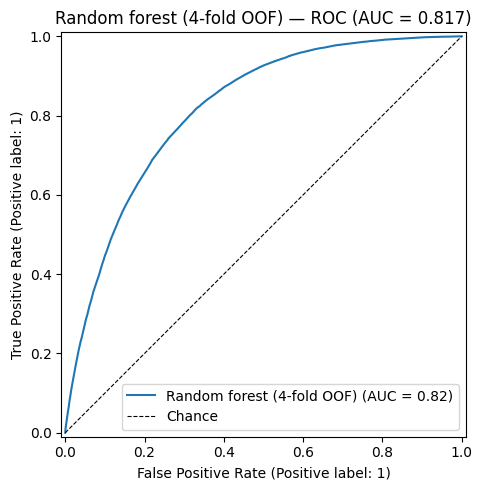

Confusion matrix (rows = true, columns = predicted):
[[24734 10612]
 [ 7586 27760]]


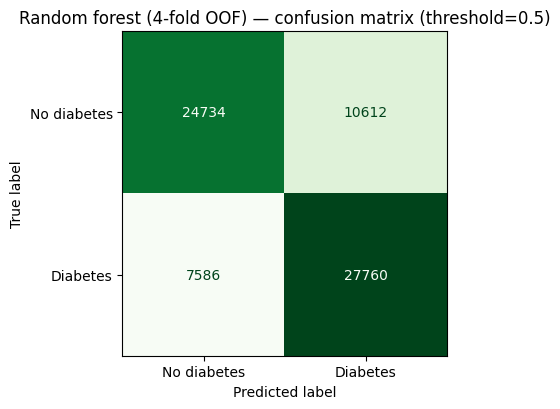

,value
accuracy,0.742573
balanced_accuracy,0.742573
precision,0.723444
recall,0.785379
f1,0.753140
roc_auc,0.817441


              precision    recall  f1-score   support

 No diabetes      0.765     0.700     0.731     35346
    Diabetes      0.723     0.785     0.753     35346

    accuracy                          0.743     70692
   macro avg      0.744     0.743     0.742     70692
weighted avg      0.744     0.743     0.742     70692


Feature importance — full-sample refit, trees=200, max_samples=30,000


,feature,importance
3,bmi,0.168260
18,age,0.125216
13,gen_hlth,0.106221
20,income,0.083447
0,high_bp,0.079901
15,phys_hlth,0.067814
19,education,0.056252
14,ment_hlth,0.051233
1,high_chol,0.040899
4,smoker,0.028683


In [35]:
# Cell 14 · Random forest — 4-fold CV & feature importance
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier

if "X" not in globals() or "y" not in globals() or "dm_run_cv" not in globals():
    raise NameError("Run Cell 13 first.")

DM_RF_MAX_SAMPLES = 30_000

dm_rf_base = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    n_jobs=1,
)

(
    dm_rf_cv_detail,
    dm_rf_cv_summary,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
) = dm_run_cv(
    dm_rf_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Random forest",
)

print("\n=== Random forest — out-of-fold evaluation ===")
dm_rf_test_metrics = _dm_binary_classification_eval(
    y,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Random forest ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Greens",
)
dm_rf_test_metrics.name = "random_forest"

dm_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
    n_jobs=1,
)
dm_rf_model.fit(X, y)

dm_rf_importance = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "importance": dm_rf_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

print(
    f"\nFeature importance — full-sample refit, trees=200, "
    f"max_samples={DM_RF_MAX_SAMPLES:,}"
)
display(dm_rf_importance.head(15))


In [36]:
# Cell 15 · Compare logistic vs random forest (4-fold CV)
from IPython.display import display

if "dm_logistic_cv_summary" not in globals() or "dm_rf_cv_summary" not in globals():
    raise NameError("Run Cells 13 and 14 first.")

dm_model_comparison = pd.DataFrame(
    {
        "logistic_regression": dm_logistic_cv_summary["mean"],
        "random_forest": dm_rf_cv_summary["mean"],
    }
)
dm_model_comparison["delta_rf_minus_logistic"] = (
    dm_model_comparison["random_forest"] - dm_model_comparison["logistic_regression"]
)

print(
    f"CV comparison — {DM_CV_FOLDS} folds, n={len(y):,}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}, "
    f"minority emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}, "
    f"random_state={DM_MODEL_RANDOM_STATE}"
)
display(dm_model_comparison.round(4))

print("\nPer-fold ROC AUC:")
display(
    pd.DataFrame(
        {
            "logistic_auc": dm_logistic_cv_detail["roc_auc"],
            "rf_auc": dm_rf_cv_detail["roc_auc"],
        }
    ).round(4)
)

auc_log = float(dm_logistic_cv_summary.loc["roc_auc", "mean"])
auc_rf = float(dm_rf_cv_summary.loc["roc_auc", "mean"])
if auc_rf > auc_log:
    winner = "random forest"
elif auc_rf < auc_log:
    winner = "logistic regression"
else:
    winner = "tie"
print(
    f"Higher mean CV ROC AUC: {winner} "
    f"(logistic={auc_log:.4f}, RF={auc_rf:.4f})."
)


CV comparison — 4 folds, n=70,692, predictors=21, minority emphasis=1.0, random_state=42


,logistic_regression,random_forest,delta_rf_minus_logistic
accuracy,0.7492,0.7426,-0.0066
balanced_accuracy,0.7492,0.7426,-0.0066
precision,0.7384,0.7234,-0.0149
recall,0.7719,0.7854,0.0135
f1,0.7548,0.7531,-0.0016
roc_auc,0.8263,0.8174,-0.0089



Per-fold ROC AUC:


,logistic_auc,rf_auc
fold,,
1,0.8281,0.8167
2,0.8242,0.8181
3,0.8258,0.8158
4,0.8273,0.8192


Higher mean CV ROC AUC: logistic regression (logistic=0.8263, RF=0.8174).
